In [ ]:
import os
import gc
import numpy as np
import scipy.io as sio
import tifffile
import matplotlib as mpl
import matplotlib.pyplot as plt

from skimage.transform import PiecewiseAffineTransform
from scipy.ndimage import map_coordinates

# Default font and axis sizes – applied once at module import.
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica Neue', 'Helvetica', 'Arial']
mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False


# ----------------------------
# Paths
# ----------------------------
# path = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg'
# path = '/Users/megyoung/Desktop/72logstack/'
# selected_tiff = "72ltask_00001.tif"
# path = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg'
# selected_tiff = "71rtask_00001.tif"
path = '/Users/megyoung/mini2p-preprocessing/data/mini2p/raw/'
selected_tiff = "71rtask_00040.tif"
tiff_path = os.path.join(path, selected_tiff)

transform_mat = '/Volumes/behrens/meg/file_00001_TransformMatrix_Far-reaching_1.0_0514213221.mat'


# ----------------------------
# Inspect TIFF
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    page0 = tif.pages[0]
    height, width = page0.shape
    dtype = page0.dtype

print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

# ----------------------------
# Destriping
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    """
    chunk shape: frames x height x width
    """
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Preserve the positive F0 and population activity by subtracting
        # only column-dependent stripe variation. False reproduces the old
        # zero-centred output for direct comparison.
        avg_forward -= np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse -= np.mean(avg_reverse, axis=2, keepdims=True)

    detrended = np.empty_like(chunk, dtype=np.float32)
    detrended[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    detrended[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return detrended


# ----------------------------
# Load piecewise transform
# ----------------------------
def load_piecewise_transform(transform_mat, z_um=0):
    mat = sio.loadmat(transform_mat, squeeze_me=True, struct_as_record=False)
    transforms = mat["TransfMatrix"]

    zs = np.array([float(t.Z) for t in transforms])
    idx = int(np.argmin(np.abs(zs - z_um)))

    T = transforms[idx]
    gp = T.GridParameter

    fixed = np.asarray(gp.Anchor_pairs_nodistortion, dtype=np.float32)
    moving = np.asarray(gp.Anchor_pairs_withdistortion, dtype=np.float32)

    print(f"Requested Z: {z_um}")
    print(f"Using transform index: {idx}")
    print(f"Matched Z: {zs[idx]}")
    print("Fixed points:", fixed.shape)
    print("Moving points:", moving.shape)

    tform = PiecewiseAffineTransform()
    ok = tform.estimate(src=moving, dst=fixed)

    if not ok:
        raise RuntimeError("Piecewise affine transform estimation failed.")

    return tform


# ----------------------------
# Precompute warp maps once
# ----------------------------
def make_warp_maps(tform, image_shape):
    h, w = image_shape

    rr, cc = np.meshgrid(
        np.arange(h),
        np.arange(w),
        indexing="ij"
    )

    coords = np.column_stack([cc.ravel(), rr.ravel()])  # x, y
    src = tform.inverse(coords)

    map_x = src[:, 0].reshape(h, w).astype(np.float32)
    map_y = src[:, 1].reshape(h, w).astype(np.float32)

    return map_y, map_x


# ----------------------------
# Fast correction using precomputed maps
# ----------------------------
def apply_piecewise_correction_fast(frame, map_y, map_x):
    corrected = map_coordinates(
        frame.astype(np.float32),
        [map_y, map_x],
        order=1,
        mode="constant",
        cval=0
    )

    return corrected.astype(np.float32)


# ----------------------------
# Preview one frame
# ----------------------------
def test_one_frame(
    tiff_path,
    transform_mat,
    channel=0,
    frame_number_in_channel=0,
    z_um=0
):
    page_idx = channel + 2 * frame_number_in_channel

    with tifffile.TiffFile(tiff_path) as tif:
        raw_frame = tif.pages[page_idx].asarray().astype(np.float32)

    destriped_frame = detrend_chunk(raw_frame[None, :, :])[0]

    tform = load_piecewise_transform(transform_mat, z_um=z_um)
    map_y, map_x = make_warp_maps(tform, raw_frame.shape)

    corrected_frame = apply_piecewise_correction_fast(
        destriped_frame,
        map_y,
        map_x
    )

    def show_autoscaled(ax, img, title, cmap="gray", p_low=1, p_high=99.8):
        vmin, vmax = np.percentile(img[np.isfinite(img)], [p_low, p_high])
        ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_title(title, pad=10)
        ax.axis("off")


    fig, axes = plt.subplots(
        1, 3, figsize=(16, 5.2), constrained_layout=True)

    show_autoscaled(axes[0], raw_frame, "Raw")
    show_autoscaled(axes[1], destriped_frame, "Destriped")
    show_autoscaled(axes[2], corrected_frame, "Destriped + corrected")

    fig.suptitle(
        f"Channel {channel + 1}, frame {frame_number_in_channel}",
        fontsize=16, fontweight="semibold")
    plt.show()

    return raw_frame, destriped_frame, corrected_frame


# ----------------------------
# Preview the mean of the first N frames
# ----------------------------
def test_first_frames(
    tiff_path,
    transform_mat,
    channel=0,
    n_frames=100,
    z_um=0,
    p_low=1,
    p_high=99.8,
):
    """Process the first N channel frames and plot their mean images."""
    with tifffile.TiffFile(tiff_path) as tif:
        available = max(0, (len(tif.pages) - channel + 1) // 2)
        n_to_load = min(int(n_frames), available)
        if n_to_load < 1:
            raise ValueError(f'No frames found for channel {channel}')
        page_indices = channel + 2 * np.arange(n_to_load)
        raw_stack = np.stack(
            [tif.pages[int(page)].asarray() for page in page_indices], axis=0
        ).astype(np.float32)

    destriped_stack = detrend_chunk(raw_stack)
    tform = load_piecewise_transform(transform_mat, z_um=z_um)
    map_y, map_x = make_warp_maps(tform, raw_stack.shape[1:])
    corrected_stack = np.stack([
        apply_piecewise_correction_fast(frame, map_y, map_x)
        for frame in destriped_stack
    ], axis=0)

    mean_images = [
        np.nanmean(raw_stack, axis=0),
        np.nanmean(destriped_stack, axis=0),
        np.nanmean(corrected_stack, axis=0),
    ]
    finite_values = np.concatenate([
        image[np.isfinite(image)].ravel() for image in mean_images
    ])
    vmin, vmax = np.percentile(finite_values, [p_low, p_high])

    fig, axes = plt.subplots(
        1, 3, figsize=(16, 5.2), constrained_layout=True)
    titles = ('Raw Mean Image', 'Destriped Mean Image', 'Destriped + Distortion Corrected Mean Image')
    for ax, image, title in zip(axes, mean_images, titles):
        ax.imshow(
            image, cmap='gray', vmin=vmin, vmax=vmax,
            interpolation='nearest')
        ax.set_title(title, pad=10)
        ax.axis('off')
    plt.show()

    return tuple(mean_images)


# ----------------------------
# Full stack processing
# ----------------------------
def destripe_and_correct_channel_python_fast(
    tiff_path,
    channel,
    output_file,
    transform_mat,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float32,
    max_frames=None
):
    if os.path.exists(output_file):
        os.remove(output_file)

    tform = load_piecewise_transform(transform_mat, z_um=z_um)

    with tifffile.TiffFile(tiff_path) as tif:
        frame_shape = tif.pages[0].shape
        map_y, map_x = make_warp_maps(tform, frame_shape)

        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)

        if max_frames is not None:
            channel_frames = channel_frames[:max_frames]

        print(f"Processing channel {channel}")
        print(f"Frames to process: {len(channel_frames)}")
        print(f"Saving to: {output_file}")

        frames_written = 0

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, len(channel_frames), chunk_size):
                end = min(start + chunk_size, len(channel_frames))
                inds = channel_frames[start:end]

                chunk = np.stack(
                    [tif.pages[int(idx)].asarray() for idx in inds],
                    axis=0
                )

                destriped = detrend_chunk(chunk)

                for frame in destriped:
                    corrected = apply_piecewise_correction_fast(
                        frame,
                        map_y,
                        map_x
                    )

                    writer.write(
                        corrected.astype(output_dtype),
                        contiguous=False
                    )

                    frames_written += 1

                print(f"Saved frames {start} to {end} / {len(channel_frames)}")

                del chunk, destriped
                gc.collect()

    print("Done:", output_file)
    print("Frames written:", frames_written)
    print("File size:", os.path.getsize(output_file), "bytes")

def destripe_and_correct_two_channels_interleaved(
    tiff_path,
    output_file,
    transform_mat=None,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float32,
    max_frames=None,
    apply_destriping=True,
    apply_distortion_correction=True,
):
    """
    Process a two-channel TIFF with interleaved pages:

        page 0 = channel 1, frame 0
        page 1 = channel 2, frame 0
        page 2 = channel 1, frame 1
        page 3 = channel 2, frame 1

    Destriping and distortion correction can be enabled independently
    using apply_destriping and apply_distortion_correction.

    The output preserves the same interleaved order.
    """

    if os.path.exists(output_file):
        os.remove(output_file)

    tform = None
    map_y = None
    map_x = None

    if apply_distortion_correction:
        if transform_mat is None:
            raise ValueError(
                "transform_mat must be supplied when "
                "apply_distortion_correction=True."
            )

        tform = load_piecewise_transform(
            transform_mat,
            z_um=z_um,
        )

    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)

        if n_pages % 2 != 0:
            raise ValueError(
                f"The TIFF contains {n_pages} pages, "
                "which is not divisible by 2."
            )

        frame_shape = tif.pages[0].shape

        if apply_distortion_correction:
            map_y, map_x = make_warp_maps(
                tform,
                frame_shape,
            )

        n_timepoints = n_pages // 2

        if max_frames is not None:
            n_timepoints = min(
                n_timepoints,
                max_frames,
            )

        print("Input:", tiff_path)
        print("Output:", output_file)
        print("Image shape:", frame_shape)
        print("Timepoints:", n_timepoints)
        print("Pages to write:", n_timepoints * 2)
        print("Destriping:", apply_destriping)
        print(
            "Distortion correction:",
            apply_distortion_correction,
        )

        pages_written = 0

        with tifffile.TiffWriter(
            output_file,
            bigtiff=True,
        ) as writer:

            for start in range(
                0,
                n_timepoints,
                chunk_size,
            ):
                end = min(
                    start + chunk_size,
                    n_timepoints,
                )

                ch1_indices = 2 * np.arange(start, end)
                ch2_indices = ch1_indices + 1

                ch1_chunk = np.stack(
                    [
                        tif.pages[int(idx)].asarray()
                        for idx in ch1_indices
                    ],
                    axis=0,
                )

                ch2_chunk = np.stack(
                    [
                        tif.pages[int(idx)].asarray()
                        for idx in ch2_indices
                    ],
                    axis=0,
                )

                if apply_destriping:
                    ch1_processed = detrend_chunk(ch1_chunk)
                    ch2_processed = detrend_chunk(ch2_chunk)
                else:
                    ch1_processed = ch1_chunk
                    ch2_processed = ch2_chunk

                for i in range(end - start):
                    if apply_distortion_correction:
                        ch1_output = (
                            apply_piecewise_correction_fast(
                                ch1_processed[i],
                                map_y,
                                map_x,
                            )
                        )

                        ch2_output = (
                            apply_piecewise_correction_fast(
                                ch2_processed[i],
                                map_y,
                                map_x,
                            )
                        )

                    else:
                        ch1_output = ch1_processed[i]
                        ch2_output = ch2_processed[i]

                    writer.write(
                        ch1_output.astype(output_dtype),
                        contiguous=False,
                    )

                    writer.write(
                        ch2_output.astype(output_dtype),
                        contiguous=False,
                    )

                    pages_written += 2

                print(
                    f"Saved timepoints {start} to {end} "
                    f"/ {n_timepoints}"
                )

                del (
                    ch1_chunk,
                    ch2_chunk,
                    ch1_processed,
                    ch2_processed,
                )

                gc.collect()

    print("Done:", output_file)
    print("Pages written:", pages_written)
    print(
        "File size:",
        os.path.getsize(output_file),
        "bytes",
    )

Height: 512
Width: 512
dtype: int16


Requested Z: 0
Using transform index: 0
Matched Z: 0.0
Fixed points: (323, 2)
Moving points: (323, 2)


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_35237/4004226228.py:99: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `PiecewiseAffineTransform.from_estimate` class constructor instead.
  ok = tform.estimate(src=moving, dst=fixed)


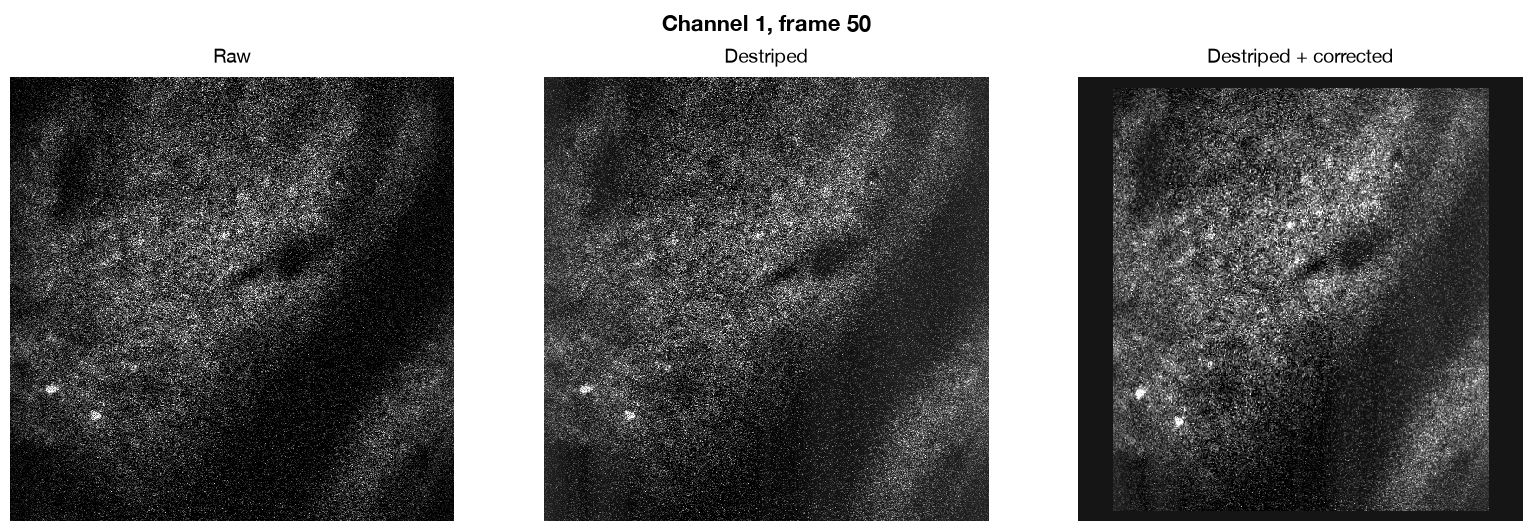

In [20]:
# ----------------------------
# 1. Test one frame first
# ----------------------------
raw_frame, destriped_frame, corrected_frame = test_one_frame(
    tiff_path=tiff_path,
    transform_mat=transform_mat,
    channel=0,
    frame_number_in_channel=50,
    z_um=0
)

Requested Z: 0
Using transform index: 0
Matched Z: 0.0
Fixed points: (323, 2)
Moving points: (323, 2)


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_35237/4004226228.py:99: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `PiecewiseAffineTransform.from_estimate` class constructor instead.
  ok = tform.estimate(src=moving, dst=fixed)


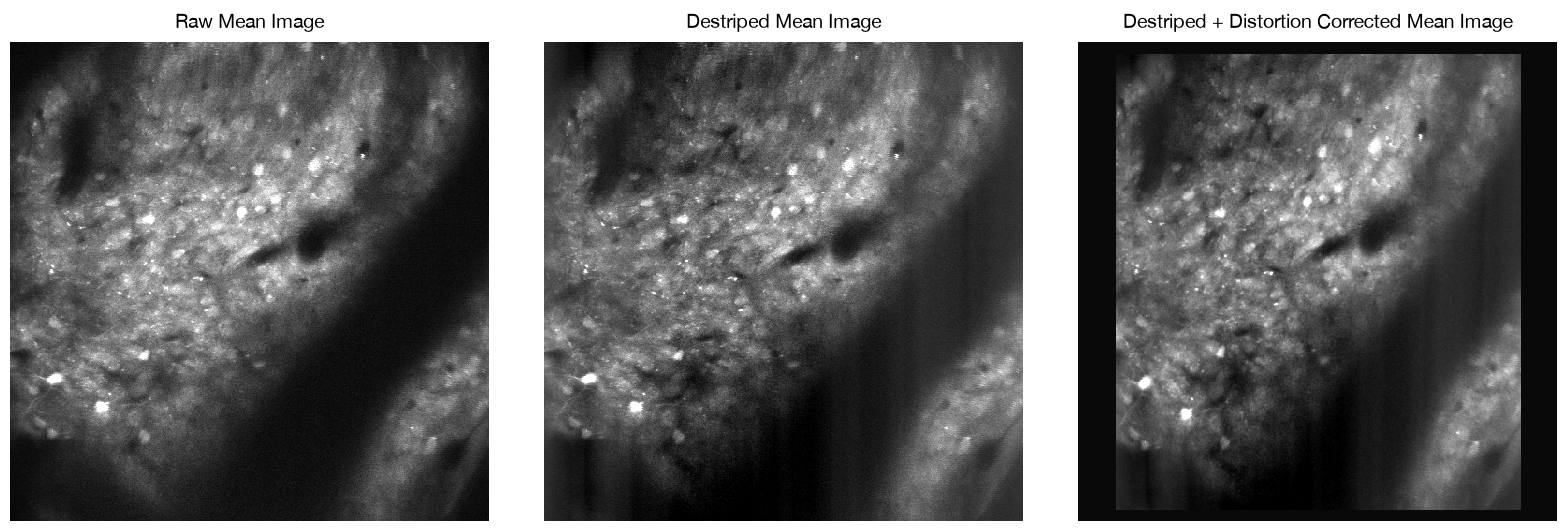

In [21]:
# ----------------------------
# 2. Test the first 100 frames
# ----------------------------
raw_mean_100, destriped_mean_100, corrected_mean_100 = test_first_frames(
    tiff_path=tiff_path,
    transform_mat=transform_mat,
    channel=0,
    n_frames=100,
    z_um=0,
)

In [53]:
# ----------------------------
# 3. Full interleaved channnels
# ----------------------------
output_file1 = os.path.join(
    path,
    "stack_destriped_distortion_uncorrected.tiff"
)

destripe_and_correct_two_channels_interleaved(
    tiff_path=tiff_path,
    output_file=output_file1,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float16,
    apply_destriping=True,
    apply_distortion_correction=False
)

Input: /Users/megyoung/Desktop/imaging_roundtwo/71R/day4/6/71rpre_00028.tif
Output: /Users/megyoung/Desktop/imaging_roundtwo/71R/day4/6/stack_destriped_distortion_uncorrected.tiff
Image shape: (512, 512)
Timepoints: 500
Pages to write: 1000
Destriping: True
Distortion correction: False
Saved timepoints 0 to 100 / 500
Saved timepoints 100 to 200 / 500
Saved timepoints 200 to 300 / 500
Saved timepoints 300 to 400 / 500
Saved timepoints 400 to 500 / 500
Done: /Users/megyoung/Desktop/imaging_roundtwo/71R/day4/6/stack_destriped_distortion_uncorrected.tiff
Pages written: 1000
File size: 524656016 bytes
